In [1]:
# Run this cell once after opening the notebook.
# It checks the project folders and locates the dataset.

from pathlib import Path
import os
import warnings

# The notebook is expected to live in RetailMind_AI/notebooks/.
# In VS Code, open the RetailMind_AI folder as the workspace.
NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name == "notebooks":
    PROJECT_ROOT = NOTEBOOK_DIR.parent
elif (NOTEBOOK_DIR / "notebooks").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
else:
    # Fallback for environments where the current directory is not obvious.
    PROJECT_ROOT = NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

for folder in [DATA_DIR, MODEL_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_CANDIDATES = [
    DATA_DIR / "Telco-Customer-Churn.csv",
    DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)

print("Project root:", PROJECT_ROOT)
print("Dataset folder:", DATA_DIR)
print("Models folder:", MODEL_DIR)
print("Reports folder:", REPORT_DIR)

if DATA_PATH is None:
    print("\nDataset not found yet. Download the Kaggle CSV and place it in data/.")
else:
    print("\nDataset found:", DATA_PATH.name)

Project root: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main
Dataset folder: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\data
Models folder: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\models
Reports folder: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\reports

Dataset found: Telco-Customer-Churn.csv


In [2]:
import numpy as np
import pandas as pd
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    learning_curve,
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TARGET = "Churn"

print("Imports completed.")

Imports completed.


In [3]:
# Locate the CSV again in case the setup cell was run before the file was copied.
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Place the Kaggle CSV in the project's data/ folder. "
        "Expected Telco-Customer-Churn.csv or WA_Fn-UseC_-Telco-Customer-Churn.csv."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn data types:")
display(df.dtypes)
print("\nChurn distribution:")
display(df[TARGET].value_counts(dropna=False))
print("\nChurn proportions:")
display(df[TARGET].value_counts(normalize=True).round(3))

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column data types:


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


Churn distribution:


No     5174
Yes    1869
Name: Churn, dtype: int64


Churn proportions:


No     0.735
Yes    0.265
Name: Churn, dtype: float64

In [4]:
# TotalCharges looks numeric but may contain blank strings in the original CSV.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# CustomerID is an identifier, not a behavioural predictor.
df = df.drop(columns=["customerID"], errors="ignore")

# Encode the target: No = 0, Yes = 1.
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})

if df[TARGET].isna().any():
    raise ValueError("Unexpected target labels. Expected only 'Yes' and 'No'.")

X = df.drop(columns=TARGET)
y = df[TARGET].astype(int)

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("\nMissing values by feature (non-zero only):")
display(X.isna().sum()[X.isna().sum() > 0])

Feature matrix: (7043, 19)
Target vector: (7043,)

Missing values by feature (non-zero only):


TotalCharges    11
dtype: int64

In [5]:
# Keep the same split for all four days so that comparisons are consistent.
# Stratification preserves approximately the same churn proportion in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)
print("\nChurn rate — train:", round(y_train.mean(), 3))
print("Churn rate — test: ", round(y_test.mean(), 3))

X_train: (5634, 19)
X_test:  (1409, 19)
y_train: (5634,)
y_test:  (1409,)

Churn rate — train: 0.265
Churn rate — test:  0.265


In [6]:
def make_preprocessor(input_frame):
    """Create numeric and categorical preprocessing based on input columns."""
    numeric_columns = input_frame.select_dtypes(include="number").columns.tolist()
    categorical_columns = input_frame.select_dtypes(exclude="number").columns.tolist()

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])


def make_model_pipeline(input_frame, estimator, use_feature_selection=False):
    """Package preprocessing and an estimator into one fitted/persistable object."""
    steps = [("preprocess", make_preprocessor(input_frame))]

    if use_feature_selection:
        # k is set later based on the transformed feature count.
        steps.append(("feature_selection", SelectKBest(score_func=f_classif, k=30)))

    steps.append(("model", estimator))
    return Pipeline(steps)


print("Preprocessing and pipeline helper functions are ready.")

Preprocessing and pipeline helper functions are ready.


In [7]:
# Logistic Regression is the Day 1 baseline.
# class_weight='balanced' asks the model to account for the unequal class counts.
baseline_pipeline = make_model_pipeline(
    X_train,
    LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
)

baseline_pipeline.fit(X_train, y_train)
print("Day 1 baseline pipeline fitted.")

Day 1 baseline pipeline fitted.


In [8]:
def evaluate_classifier(model_name, fitted_pipeline, features, target, show_details=True):
    """Calculate consistent metrics. Churn=Yes (1) is the positive class."""
    predictions = fitted_pipeline.predict(features)

    if hasattr(fitted_pipeline, "predict_proba"):
        continuous_scores = fitted_pipeline.predict_proba(features)[:, 1]
    else:
        continuous_scores = fitted_pipeline.decision_function(features)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(target, predictions),
        "Precision": precision_score(target, predictions, zero_division=0),
        "Recall": recall_score(target, predictions, zero_division=0),
        "F1": f1_score(target, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(target, continuous_scores),
    }

    if show_details:
        display(pd.DataFrame([metrics]).set_index("Model"))
        print("Confusion matrix [[TN, FP], [FN, TP]]:")
        print(confusion_matrix(target, predictions))
        print("\nClassification report:")
        print(classification_report(
            target,
            predictions,
            target_names=["No Churn", "Churn"],
            zero_division=0,
        ))

    return metrics


day1_metrics = evaluate_classifier(
    "Day 1 — Logistic Regression baseline",
    baseline_pipeline,
    X_test,
    y_test,
)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 1 — Logistic Regression baseline,0.738112,0.504303,0.783422,0.613613,0.841461


Confusion matrix [[TN, FP], [FN, TP]]:
[[747 288]
 [ 81 293]]

Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [9]:
# Save the fitted preprocessing + classifier together.
day1_model_path = MODEL_DIR / "churn_day1_baseline.joblib"
joblib.dump(baseline_pipeline, day1_model_path)

# A small inference helper: new customer records go in; labels and probabilities come out.
def predict_churn(customer_rows, fitted_model=baseline_pipeline):
    """Predict churn label and churn probability for a DataFrame of customer records."""
    churn_labels = fitted_model.predict(customer_rows)
    churn_probabilities = fitted_model.predict_proba(customer_rows)[:, 1]

    return pd.DataFrame({
        "predicted_churn": churn_labels,
        "churn_probability": churn_probabilities,
    }, index=customer_rows.index)


print("Saved:", day1_model_path)
display(predict_churn(X_test.head()))

Saved: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\models\churn_day1_baseline.joblib


,predicted_churn,churn_probability
437,0,0.116401
2280,1,0.852299
2235,0,0.146072
4460,1,0.660832
3761,0,0.060568


In [10]:
day2_candidates = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
    ),
    "SVM": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

print("Candidate models:", list(day2_candidates))

Candidate models: ['Decision Tree', 'Random Forest', 'SVM']


In [11]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

day2_fitted = {}
day2_rows = []

for model_name, estimator in day2_candidates.items():
    candidate_pipeline = make_model_pipeline(X_train, estimator)

    # Cross-validation is run only on the training portion.
    cv_recall = cross_val_score(
        candidate_pipeline,
        X_train,
        y_train,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1,
    ).mean()

    candidate_pipeline.fit(X_train, y_train)
    day2_fitted[model_name] = candidate_pipeline

    test_metrics = evaluate_classifier(
        f"Day 2 — {model_name}",
        candidate_pipeline,
        X_test,
        y_test,
        show_details=False,
    )
    test_metrics["CV_Recall"] = cv_recall
    day2_rows.append(test_metrics)

day2_comparison = pd.DataFrame(day2_rows).sort_values(
    "CV_Recall", ascending=False
)
display(day2_comparison)
day2_comparison.to_csv(REPORT_DIR / "day2_model_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall
2,Day 2 — SVM,0.743790,0.511504,0.772727,0.615548,0.821065,0.779253
0,Day 2 — Decision Tree,0.728176,0.487805,0.481283,0.484522,0.649570,0.487626
1,Day 2 — Random Forest,0.781405,0.616197,0.467914,0.531915,0.821288,0.460886


In [12]:
# Champion selection uses cross-validation recall, not test-set recall.
day2_champion_name = day2_comparison.iloc[0]["Model"].replace("Day 2 — ", "")
day2_champion = day2_fitted[day2_champion_name]

day2_champion_path = MODEL_DIR / "churn_day2_champion.joblib"
joblib.dump(day2_champion, day2_champion_path)

print("Day 2 champion:", day2_champion_name)
print("Selection basis: highest mean cross-validation recall on training data.")
print("Saved:", day2_champion_path)

Day 2 champion: SVM
Selection basis: highest mean cross-validation recall on training data.
Saved: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\models\churn_day2_champion.joblib


In [13]:
day3_search_spaces = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
        {
            "model__max_depth": [4, 8, None],
            "model__min_samples_leaf": [1, 5],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1,
        ),
        {
            "model__n_estimators": [150, 250],
            "model__max_depth": [None, 10],
            "model__min_samples_leaf": [1, 3],
        },
    ),
    "SVM": (
        SVC(kernel="rbf", probability=True, class_weight="balanced"),
        {
            "model__C": [0.5, 1, 3],
            "model__gamma": ["scale", "auto"],
        },
    ),
}

print("Search spaces defined.")

Search spaces defined.


In [14]:
day3_tuned_models = {}
day3_rows = []

for model_name, (estimator, parameter_grid) in day3_search_spaces.items():
    print(f"Running grid search for {model_name} ...")

    search_pipeline = make_model_pipeline(X_train, estimator)

    search = GridSearchCV(
        estimator=search_pipeline,
        param_grid=parameter_grid,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1,
        refit=True,
    )

    search.fit(X_train, y_train)
    day3_tuned_models[model_name] = search.best_estimator_

    day3_rows.append({
        "Model": model_name,
        "Best_CV_Recall": search.best_score_,
        "Best_Parameters": search.best_params_,
    })

day3_cv_results = pd.DataFrame(day3_rows).sort_values(
    "Best_CV_Recall", ascending=False
)
display(day3_cv_results)
day3_cv_results.to_csv(REPORT_DIR / "day3_cv_tuning_results.csv", index=False)

Running grid search for Decision Tree ...
Running grid search for Random Forest ...
Running grid search for SVM ...


,Model,Best_CV_Recall,Best_Parameters
2,SVM,0.817383,"{'model__C': 0.5, 'model__gamma': 'auto'}"
0,Decision Tree,0.779271,"{'model__max_depth': 4, 'model__min_samples_le..."
1,Random Forest,0.727761,"{'model__max_depth': 10, 'model__min_samples_l..."


In [15]:
# Choose the model using training cross-validation results.
day3_champion_name = day3_cv_results.iloc[0]["Model"]
day3_champion = day3_tuned_models[day3_champion_name]

day3_champion_path = MODEL_DIR / "churn_day3_tuned.joblib"
joblib.dump(day3_champion, day3_champion_path)

print("Day 3 champion:", day3_champion_name)
print("Best CV recall:", round(day3_cv_results.iloc[0]["Best_CV_Recall"], 4))
print("Saved:", day3_champion_path)

day3_metrics = evaluate_classifier(
    f"Day 3 — Tuned {day3_champion_name}",
    day3_champion,
    X_test,
    y_test,
)

Day 3 champion: SVM
Best CV recall: 0.8174
Saved: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\models\churn_day3_tuned.joblib


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 3 — Tuned SVM,0.723918,0.487844,0.804813,0.607467,0.832957


Confusion matrix [[TN, FP], [FN, TP]]:
[[719 316]
 [ 73 301]]

Classification report:
              precision    recall  f1-score   support

    No Churn       0.91      0.69      0.79      1035
       Churn       0.49      0.80      0.61       374

    accuracy                           0.72      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.72      0.74      1409



In [16]:
# Training recall and validation recall help diagnose generalisation.
# A large gap can indicate overfitting; both scores being low can indicate underfitting.
train_sizes, train_scores, validation_scores = learning_curve(
    day3_champion,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring="recall",
    train_sizes=np.linspace(0.5, 1.0, 3),
    n_jobs=-1,
)

learning_curve_results = pd.DataFrame({
    "Training_Size": train_sizes,
    "Mean_Training_Recall": train_scores.mean(axis=1),
    "Mean_CV_Recall": validation_scores.mean(axis=1),
})
display(learning_curve_results)
learning_curve_results.to_csv(REPORT_DIR / "day3_learning_curve.csv", index=False)

,Training_Size,Mean_Training_Recall,Mean_CV_Recall
0,1878,0.831416,0.806008
1,2817,0.832211,0.818051
2,3756,0.822076,0.817383


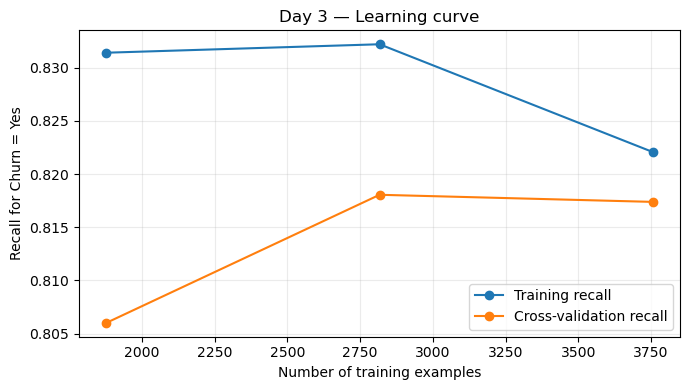

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training recall",
)
plt.plot(
    train_sizes,
    validation_scores.mean(axis=1),
    marker="o",
    label="Cross-validation recall",
)
plt.xlabel("Number of training examples")
plt.ylabel("Recall for Churn = Yes")
plt.title("Day 3 — Learning curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_DIR / "day3_learning_curve.png", dpi=140)
plt.show()

In [18]:
def add_customer_features(input_frame):
    """Add simple, explainable features without using the target column."""
    engineered = input_frame.copy()

    if "tenure" in engineered.columns:
        tenure = pd.to_numeric(engineered["tenure"], errors="coerce")
        engineered["tenure_group"] = pd.cut(
            tenure,
            bins=[-1, 12, 24, 48, 72],
            labels=["0-12", "13-24", "25-48", "49-72"],
        ).astype("object")

    if {"TotalCharges", "tenure"}.issubset(engineered.columns):
        total = pd.to_numeric(engineered["TotalCharges"], errors="coerce")
        tenure = pd.to_numeric(engineered["tenure"], errors="coerce").replace(0, np.nan)
        engineered["average_charge_per_month"] = total / tenure

    if "Contract" in engineered.columns:
        engineered["is_month_to_month"] = (
            engineered["Contract"] == "Month-to-month"
        ).astype(int)

    if "PaymentMethod" in engineered.columns:
        engineered["uses_electronic_check"] = (
            engineered["PaymentMethod"] == "Electronic check"
        ).astype(int)

    return engineered


X_train_day4 = add_customer_features(X_train)
X_test_day4 = add_customer_features(X_test)

print("Original feature count:", X_train.shape[1])
print("Feature count after engineering:", X_train_day4.shape[1])
display(X_train_day4.head())

Original feature count: 19
Feature count after engineering: 23


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,average_charge_per_month,is_month_to_month,uses_electronic_check
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,...,Yes,Month-to-month,No,Electronic check,49.20,1701.65,25-48,48.618571,1,1
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,...,No,Month-to-month,No,Mailed check,75.10,1151.55,13-24,76.770000,1,0
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,...,No,Two year,No,Mailed check,40.55,590.35,13-24,45.411538,0,0
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,...,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,25-48,73.296154,0,0
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,...,No,Month-to-month,No,Electronic check,44.55,44.55,0-12,44.550000,1,1


In [19]:
def make_day4_pipeline(input_frame, estimator):
    """Preprocess, select the top 30 transformed features, then fit the estimator.

    Telco's one-hot encoded feature set contains more than 30 columns.
    Preprocessing and feature selection remain inside the Pipeline so they
    are refitted separately within each cross-validation fold.
    """
    return Pipeline(steps=[
        ("preprocess", make_preprocessor(input_frame)),
        ("feature_selection", SelectKBest(score_func=f_classif, k=30)),
        ("model", estimator),
    ])


print("Day 4 pipeline helper is ready.")

Day 4 pipeline helper is ready.


In [20]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [21]:
day4_candidates = {
    "Random Forest + SelectKBest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

# XGBoost is optional. The Random Forest experiment still runs if it is absent.
try:
    from xgboost import XGBClassifier

    day4_candidates["XGBoost + SelectKBest"] = XGBClassifier(
        n_estimators=250,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    print("XGBoost is available.")
except ImportError:
    print("XGBoost is not installed. Random Forest will run; install xgboost to add the boosting candidate.")

print("Candidates:", list(day4_candidates))

XGBoost is available.
Candidates: ['Random Forest + SelectKBest', 'XGBoost + SelectKBest']


In [22]:
day4_fitted = {}
day4_rows = []

for model_name, estimator in day4_candidates.items():
    print(f"Cross-validating {model_name} ...")
    candidate_pipeline = make_day4_pipeline(X_train_day4, estimator)

    cv_recall_scores = cross_val_score(
        candidate_pipeline,
        X_train_day4,
        y_train,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1,
    )

    # Fit the final candidate on all training rows after CV evaluation.
    candidate_pipeline.fit(X_train_day4, y_train)
    day4_fitted[model_name] = candidate_pipeline

    test_metrics = evaluate_classifier(
        f"Day 4 — {model_name}",
        candidate_pipeline,
        X_test_day4,
        y_test,
        show_details=False,
    )
    test_metrics["CV_Recall_Mean"] = cv_recall_scores.mean()
    test_metrics["CV_Recall_Std"] = cv_recall_scores.std()
    day4_rows.append(test_metrics)

day4_comparison = pd.DataFrame(day4_rows).sort_values(
    "CV_Recall_Mean", ascending=False
)
display(day4_comparison)
day4_comparison.to_csv(REPORT_DIR / "day4_ensemble_comparison.csv", index=False)

Cross-validating Random Forest + SelectKBest ...
Cross-validating XGBoost + SelectKBest ...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall_Mean,CV_Recall_Std
0,Day 4 — Random Forest + SelectKBest,0.773598,0.566910,0.622995,0.593631,0.825715,0.625429,0.020682
1,Day 4 — XGBoost + SelectKBest,0.799858,0.657534,0.513369,0.576577,0.841369,0.517080,0.028277


In [23]:
# The Day 3 champion uses the original input columns.
# Day 4 candidates use the engineered input columns.
# Both are evaluated on the same held-out customer rows.
day3_reference_metrics = evaluate_classifier(
    f"Day 3 champion — {day3_champion_name}",
    day3_champion,
    X_test,
    y_test,
    show_details=False,
)

comparison_rows = [{
    **day3_reference_metrics,
    "CV_Recall_Mean": np.nan,
    "CV_Recall_Std": np.nan,
}]
comparison_rows.extend(day4_rows)

day4_vs_day3 = pd.DataFrame(comparison_rows)
display(day4_vs_day3)
day4_vs_day3.to_csv(REPORT_DIR / "day4_vs_day3_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall_Mean,CV_Recall_Std
0,Day 3 champion — SVM,0.723918,0.487844,0.804813,0.607467,0.832957,NaN,NaN
1,Day 4 — Random Forest + SelectKBest,0.773598,0.566910,0.622995,0.593631,0.825715,0.625429,0.020682
2,Day 4 — XGBoost + SelectKBest,0.799858,0.657534,0.513369,0.576577,0.841369,0.517080,0.028277


In [24]:
# # ==========================================
# # DAY 4 vs DAY 3 MODEL COMPARISON
# # ==========================================

# # Evaluate Day 3 champion using original input columns.
# day3_reference_metrics = evaluate_classifier(
#     f"Day 3 champion — {day3_champion_name}",
#     day3_champion,
#     X_test,
#     y_test,
#     show_details=False,
# )

# # Combine Day 3 reference metrics with Day 4 results.
# comparison_rows = [{
#     **day3_reference_metrics,
#     "CV_Recall_Mean": np.nan,
#     "CV_Recall_Std": np.nan,
# }]

# comparison_rows.extend(day4_rows)

# day4_vs_day3 = pd.DataFrame(comparison_rows)

# display(day4_vs_day3)

# # Save comparison report.
# day4_vs_day3.to_csv(
#     REPORT_DIR / "day4_vs_day3_comparison.csv",
#     index=False
# )


# # ==========================================
# # DAY 4 CHAMPION PROMOTION
# # ==========================================

# # Select champion based on training-only CV recall.
# day4_champion_name = day4_comparison.iloc[0]["Model"]
# day4_champion = day4_fitted[day4_champion_name]

# # Save promoted model.
# day4_champion_path = MODEL_DIR / "churn_day4_champion.joblib"

# joblib.dump(day4_champion, day4_champion_path)

# print("Day 4 champion:", day4_champion_name)
# print(
#     "Mean CV recall:",
#     round(day4_comparison.iloc[0]["CV_Recall_Mean"], 4)
# )
# print("Saved:", day4_champion_path)


# # ==========================================
# # FINAL HELD-OUT TEST EVALUATION
# # ==========================================

# day4_final_metrics = evaluate_classifier(
#     f"Day 4 champion — {day4_champion_name}",
#     day4_champion,
#     X_test_day4,
#     y_test,
# )

In [25]:
print("Models in day4_comparison:")
print(day4_comparison["Model"].tolist())

print("\nKeys in day4_fitted:")
print(list(day4_fitted.keys()))

Models in day4_comparison:
['Day 4 — Random Forest + SelectKBest', 'Day 4 — XGBoost + SelectKBest']

Keys in day4_fitted:
['Random Forest + SelectKBest', 'XGBoost + SelectKBest']


In [26]:
# Champion promotion based on training-only CV recall.
day4_champion_name = day4_comparison.iloc[0]["Model"]

# Match the model name with the dictionary key.
day4_model_key = day4_champion_name.replace("Day 4 — ", "")

# Retrieve the fitted model.
day4_champion = day4_fitted[day4_model_key]

# Save champion model.
day4_champion_path = MODEL_DIR / "churn_day4_champion.joblib"
joblib.dump(day4_champion, day4_champion_path)

print("Day 4 champion:", day4_champion_name)
print("Mean CV recall:", round(day4_comparison.iloc[0]["CV_Recall_Mean"], 4))
print("Saved:", day4_champion_path)

# Final held-out test evaluation.
day4_final_metrics = evaluate_classifier(
    day4_champion_name,
    day4_champion,
    X_test_day4,
    y_test,
)

Day 4 champion: Day 4 — Random Forest + SelectKBest
Mean CV recall: 0.6254
Saved: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\models\churn_day4_champion.joblib


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 4 — Random Forest + SelectKBest,0.773598,0.56691,0.622995,0.593631,0.825715


Confusion matrix [[TN, FP], [FN, TP]]:
[[857 178]
 [141 233]]

Classification report:
              precision    recall  f1-score   support

    No Churn       0.86      0.83      0.84      1035
       Churn       0.57      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409



In [27]:
# Day 5 — imports and reproducibility
import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
from sklearn.utils.class_weight import compute_class_weight

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
except ImportError as exc:
    raise ImportError(
        "Day 5 requires TensorFlow. Install it in this notebook environment "
        "with: %pip install tensorflow"
    ) from exc

DAY5_RANDOM_STATE = 42
np.random.seed(DAY5_RANDOM_STATE)
random.seed(DAY5_RANDOM_STATE)
tf.random.set_seed(DAY5_RANDOM_STATE)

# Reuse project paths from Day 1. Define safe fallbacks if this cell is run alone
# after the earlier data/model setup cells.
if "MODEL_DIR" not in globals():
    from pathlib import Path
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    MODEL_DIR = PROJECT_ROOT / "models"
    REPORT_DIR = PROJECT_ROOT / "reports"
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

TensorFlow: 2.13.0
Training rows: 5634 | Test rows: 1409


In [28]:
# MNIST warm-up: flatten 28x28 images, then use dense layers.
(x_mnist_train, y_mnist_train), (x_mnist_test, y_mnist_test) = keras.datasets.mnist.load_data()

x_mnist_train = x_mnist_train.astype("float32") / 255.0
x_mnist_test = x_mnist_test.astype("float32") / 255.0

mnist_model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="mnist_warmup")

mnist_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

mnist_history = mnist_model.fit(
    x_mnist_train, y_mnist_train,
    validation_split=0.1,
    epochs=3,
    batch_size=128,
    verbose=1,
)

mnist_loss, mnist_accuracy = mnist_model.evaluate(
    x_mnist_test, y_mnist_test, verbose=0
)
print(f"MNIST test accuracy: {mnist_accuracy:.4f}")

11490434/11490434 [==============================] - 5s 0us/step
Epoch 1/3
422/422 [==============================] - 2s 3ms/step - loss: 0.3463 - accuracy: 0.9031 - val_loss: 0.1410 - val_accuracy: 0.9583
Epoch 2/3
422/422 [==============================] - 1s 3ms/step - loss: 0.1468 - accuracy: 0.9566 - val_loss: 0.1101 - val_accuracy: 0.9670
Epoch 3/3
422/422 [==============================] - 1s 3ms/step - loss: 0.1012 - accuracy: 0.9698 - val_loss: 0.0936 - val_accuracy: 0.9730
MNIST test accuracy: 0.9684


In [29]:
# The classical Day 4 model uses engineered features, but the ANN starts with
# the same original feature set used by the earlier baseline models.
day5_preprocessor = make_preprocessor(X_train)
X_train_day5 = day5_preprocessor.fit_transform(X_train)
X_test_day5 = day5_preprocessor.transform(X_test)

# Keras dense layers expect dense float arrays.
X_train_day5 = np.asarray(X_train_day5, dtype=np.float32)
X_test_day5 = np.asarray(X_test_day5, dtype=np.float32)
y_train_day5 = np.asarray(y_train, dtype=np.float32)
y_test_day5 = np.asarray(y_test, dtype=np.int32)

print("ANN training matrix:", X_train_day5.shape)
print("ANN test matrix:", X_test_day5.shape)
print("Input features after preprocessing:", X_train_day5.shape[1])

ANN training matrix: (5634, 45)
ANN test matrix: (1409, 45)
Input features after preprocessing: 45


In [30]:
input_width = X_train_day5.shape[1]

churn_ann = keras.Sequential([
    keras.Input(shape=(input_width,), name="customer_features"),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.15),
    layers.Dense(1, activation="sigmoid", name="churn_probability"),
], name="retailmind_churn_ann")

churn_ann.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)

classes = np.unique(y_train_day5.astype(int))
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_day5.astype(int),
)
day5_class_weights = {int(label): float(weight) for label, weight in zip(classes, weights)}

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    min_delta=0.0005,
    restore_best_weights=True,
    verbose=1,
)

day5_history = churn_ann.fit(
    X_train_day5,
    y_train_day5,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    class_weight=day5_class_weights,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/100
141/141 [==============================] - 1s 4ms/step - loss: 0.5728 - accuracy: 0.6863 - precision: 0.4461 - recall: 0.7383 - auc: 0.7718 - val_loss: 0.5688 - val_accuracy: 0.7107 - val_precision: 0.4694 - val_recall: 0.8068 - val_auc: 0.8174
Epoch 2/100
141/141 [==============================] - 0s 2ms/step - loss: 0.5114 - accuracy: 0.7488 - precision: 0.5186 - recall: 0.7883 - auc: 0.8284 - val_loss: 0.5310 - val_accuracy: 0.7303 - val_precision: 0.4903 - val_recall: 0.7695 - val_auc: 0.8227
Epoch 3/100
141/141 [==============================] - 0s 2ms/step - loss: 0.4932 - accuracy: 0.7588 - precision: 0.5312 - recall: 0.8025 - auc: 0.8403 - val_loss: 0.5426 - val_accuracy: 0.7028 - val_precision: 0.4611 - val_recall: 0.8034 - val_auc: 0.8250
Epoch 4/100
141/141 [==============================] - 0s 2ms/step - loss: 0.4919 - accuracy: 0.7537 - precision: 0.5242 - recall: 0.8117 - auc: 0.8423 - val_loss: 0.4989 - val_accuracy: 0.7400 - val_precision: 0.5023 - val_recal

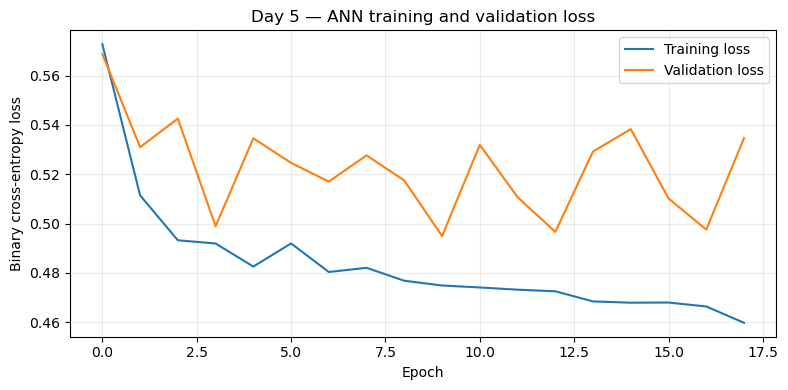

Best validation-loss epoch: 10
Epochs actually run: 18


In [31]:
# Plot training vs validation loss to inspect convergence and overfitting.
plt.figure(figsize=(8, 4))
plt.plot(day5_history.history["loss"], label="Training loss")
plt.plot(day5_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Day 5 — ANN training and validation loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_DIR / "day5_ann_loss_curve.png", dpi=140)
plt.show()

best_epoch = int(np.argmin(day5_history.history["val_loss"]) + 1)
print("Best validation-loss epoch:", best_epoch)
print("Epochs actually run:", len(day5_history.history["loss"]))

In [32]:
# ANN predictions and common binary-classification metrics.
day5_ann_probabilities = churn_ann.predict(X_test_day5, verbose=0).ravel()
day5_ann_predictions = (day5_ann_probabilities >= 0.5).astype(int)

def day5_metric_row(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
    }

day5_ann_metrics = day5_metric_row(
    "Day 5 — Keras ANN",
    y_test_day5,
    day5_ann_predictions,
    day5_ann_probabilities,
)

print("ANN confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test_day5, day5_ann_predictions))
print("\nANN classification report:")
print(classification_report(
    y_test_day5,
    day5_ann_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0,
))
display(pd.DataFrame([day5_ann_metrics]).set_index("Model"))

# Resolve the Phase-1 champion. Day 4's promoted champion is the strongest
# classical candidate selected using training-only cross-validation recall.
if "day4_champion" not in globals():
    from pathlib import Path
    possible_champion_path = MODEL_DIR / "churn_day4_champion.joblib"
    if possible_champion_path.exists():
        day4_champion = joblib.load(possible_champion_path)
    else:
        raise NameError(
            "Phase-1 champion not found. Run the Day 4 champion-promotion cell "
            "before this benchmark."
        )

if "X_test_day4" not in globals():
    X_test_day4 = add_customer_features(X_test)

champion_predictions = day4_champion.predict(X_test_day4)
if hasattr(day4_champion, "predict_proba"):
    champion_probabilities = day4_champion.predict_proba(X_test_day4)[:, 1]
else:
    champion_probabilities = day4_champion.decision_function(X_test_day4)

champion_metrics = day5_metric_row(
    "Phase-1 champion — Day 4 classical model",
    y_test_day5,
    champion_predictions,
    champion_probabilities,
)

day5_benchmark = pd.DataFrame([champion_metrics, day5_ann_metrics])
display(day5_benchmark.round(4))
day5_benchmark.to_csv(REPORT_DIR / "day5_ann_vs_phase1_champion.csv", index=False)

print("Phase-1 champion:", globals().get("day4_champion_name", "Day 4 saved champion"))

ANN confusion matrix [[TN, FP], [FN, TP]]:
[[789 246]
 [ 95 279]]

ANN classification report:
              precision    recall  f1-score   support

    No Churn       0.89      0.76      0.82      1035
       Churn       0.53      0.75      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 5 — Keras ANN,0.757984,0.531429,0.745989,0.62069,0.839533


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Phase-1 champion — Day 4 classical model,0.7736,0.5669,0.623,0.5936,0.8257
1,Day 5 — Keras ANN,0.7580,0.5314,0.746,0.6207,0.8395


Phase-1 champion: Day 4 — Random Forest + SelectKBest


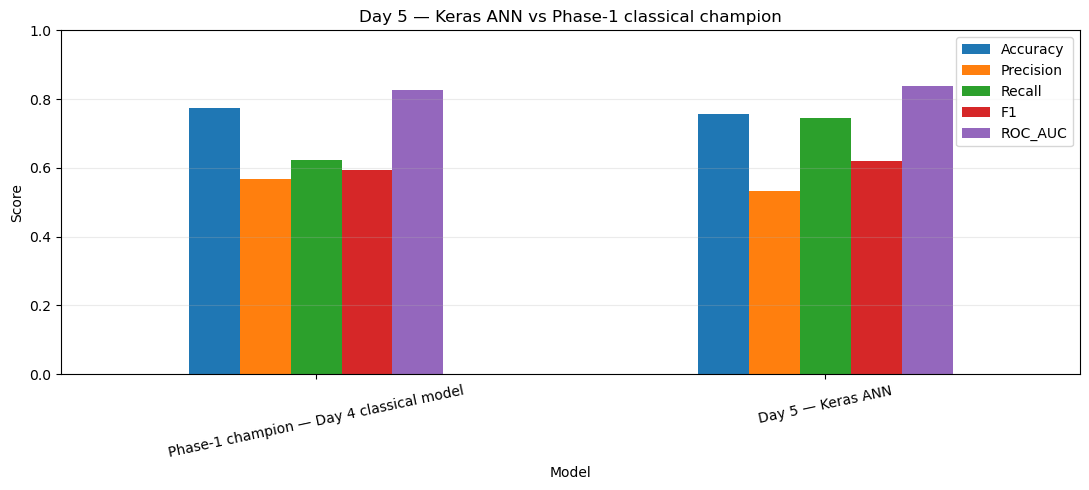

Day 5 benchmark verdict:
The ANN achieved higher held-out churn recall in this run. Consider it when missing a likely-to-churn customer is especially costly, after checking precision, ROC-AUC, stability, and operational constraints.


In [33]:
# Compare the metrics visually. Higher is better for all five metrics.
metric_columns = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
day5_benchmark.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1), rot=12
)
plt.ylabel("Score")
plt.title("Day 5 — Keras ANN vs Phase-1 classical champion")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_DIR / "day5_ann_vs_phase1_champion.png", dpi=140)
plt.show()

# Recall is the primary selection metric in this churn project.
champion_recall = float(champion_metrics["Recall"])
ann_recall = float(day5_ann_metrics["Recall"])
if ann_recall > champion_recall:
    day5_verdict = (
        "The ANN achieved higher held-out churn recall in this run. "
        "Consider it when missing a likely-to-churn customer is especially costly, "
        "after checking precision, ROC-AUC, stability, and operational constraints."
    )
elif ann_recall < champion_recall:
    day5_verdict = (
        "The classical champion achieved higher held-out churn recall in this run. "
        "Prefer the classical model when recall is the priority and the ANN does not "
        "provide a compensating advantage in other metrics."
    )
else:
    day5_verdict = (
        "The ANN and classical champion tied on held-out churn recall in this run. "
        "Compare precision, F1, ROC-AUC, complexity, latency, and maintainability "
        "before choosing."
    )

print("Day 5 benchmark verdict:")
print(day5_verdict)

In [34]:
day5_ann_path = MODEL_DIR / "churn_day5_ann.keras"
day5_preprocessor_path = MODEL_DIR / "churn_day5_preprocessor.joblib"

churn_ann.save(day5_ann_path)
joblib.dump(day5_preprocessor, day5_preprocessor_path)

print("Saved ANN:", day5_ann_path)
print("Saved preprocessor:", day5_preprocessor_path)

def predict_churn_day5(customer_rows):
    """Return ANN churn labels and probabilities for raw customer DataFrame rows."""
    transformed_rows = day5_preprocessor.transform(customer_rows)
    transformed_rows = np.asarray(transformed_rows, dtype=np.float32)
    probabilities = churn_ann.predict(transformed_rows, verbose=0).ravel()
    labels = (probabilities >= 0.5).astype(int)
    return pd.DataFrame({
        "predicted_churn": labels,
        "churn_probability": probabilities,
    }, index=customer_rows.index)

display(predict_churn_day5(X_test.head()))

Saved ANN: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\models\churn_day5_ann.keras
Saved preprocessor: c:\Retail-mind\RetailMind_Project-main\RetailMind_Project-main\models\churn_day5_preprocessor.joblib


,predicted_churn,churn_probability
437,0,0.125970
2280,1,0.824923
2235,0,0.161366
4460,1,0.540657
3761,0,0.081265
